# Client Data Analysis Report
**Prepared by:** Thabiso  
**Date:** 17 November 2026  
**Client:** ProDeliver Logistics (practice client)  
**Assessment window:** 17:00–20:00 SAST

---

## 1. Executive Summary
*(Fill last — 3 bullets.)*

- ...
- ...
- ...

## 2. Data Overview
**✅ PHASE 1 COMPLETE — see findings below. This is exactly the level of detail to reproduce in the real assessment.**

**Schema received:** 5 tables — customers (84 rows), orders (2,460), deliveries (2,460), payments (2,460), products (15). Orders span **June 2025 – October 2026**.

**Data quality issues found:**

| Issue | Table | Rows affected | Impact | How handled |
|---|---|---|---|---|
| Duplicate records | orders | 60 duplicate order_ids | Would double-count revenue & order counts | `SELECT DISTINCT` into clean view |
| Duplicate records | customers | 4 customer_ids duplicated | Minor — customer counts slightly inflated | `SELECT DISTINCT` into clean view |
| NULL values | deliveries.actual_date | 126 | Delivery-late metrics exclude these orders | Filtered; disclosed in Caveats |
| NULL values | payments.amount & payment_date | 160 each | Cannot confirm payment for these orders | Treated as unpaid; disclosed |
| NULL values | customers.city / sector | 8 / 16 | Grouping by city/sector slightly understated | Kept as 'Unknown'; disclosed |
| Inconsistent casing | customers.city | 15 rows ('jhb', 'PRETORIA') | Splits Johannesburg/Pretoria into fake categories | Standardised: `UPPER(TRIM(city))` |
| Inconsistent casing | customers.sector, payments.method, products.category | 29 / 533 / 4 rows | Splits categories into duplicates | Standardised: first-letter-upper |

**Key assumptions:**
1. Revenue = `quantity × unit_price`; no revenue column was provided.
2. Cancelled orders excluded from revenue; 'returned' included at full value (refund data unavailable).
3. Deliveries with NULL actual_date are treated as 'delivery outcome unknown', not 'on time'.
4. Orders with NULL payment amount/date treated as unpaid for the at-risk analysis.

**Why this matters:** uncorrected, the 60 duplicate order rows alone would have overstated order volume by ~2.4%, and split casing would have shown 'Logistics' and 'logistics' as two different service lines.

In [7]:
import os
import sqlite3

print("Working directory:", os.getcwd())
print("Database Exists:", os.path.exists("prodeliver_assessment.db"))

con = sqlite3.connect("prodeliver_assessment.db")

tables=pd.read_sql("""SELECT name FROM sqlite_master WHERE type='table'""", con)

print(tables)

Working directory: /Users/thabisoblessed/Downloads/prodeliver-assessment
Database Exists: True
         name
0   customers
1    products
2      orders
3  deliveries
4    payments


In [8]:
import sqlite3, pandas as pd
con = sqlite3.connect("prodeliver_assessment.db")

# 1) DUPLICATES — check every table's primary key
dup_orders = pd.read_sql('''
SELECT order_id, COUNT(*) AS row_count FROM orders
GROUP BY order_id HAVING COUNT(*) > 1''', con)
print("Duplicate order_ids:", len(dup_orders), "->", dup_orders['row_count'].sum(), "extra rows")

dup_customers = pd.read_sql('''
SELECT customer_id, COUNT(*) AS row_count FROM customers
GROUP BY customer_id HAVING COUNT(*) > 1''', con)
print("Duplicate customer_ids:", len(dup_customers))

Duplicate order_ids: 60 -> 120 extra rows
Duplicate customer_ids: 4


In [1]:
# 2) NULLs — count per column in one pass
nulls = pd.read_sql('''
SELECT 'customers.city' AS col, SUM(city IS NULL) AS nulls FROM customers UNION ALL
SELECT 'customers.sector', SUM(sector IS NULL) FROM customers UNION ALL
SELECT 'deliveries.actual_date', SUM(actual_date IS NULL) FROM deliveries UNION ALL
SELECT 'payments.amount', SUM(amount IS NULL) FROM payments UNION ALL
SELECT 'payments.payment_date', SUM(payment_date IS NULL) FROM payments UNION ALL
SELECT 'payments.method', SUM(method IS NULL) FROM payments''', con)
print(nulls.to_string(index=False))

                   col  nulls
        customers.city      8
      customers.sector     16
deliveries.actual_date    126
       payments.amount    160
 payments.payment_date    160
   payments.method     526

In [9]:
# 3) INCONSISTENT VALUES — GROUP BY every categorical column and eyeball it
for col, t in [("city","customers"),("sector","customers"),("method","payments"),("category","products")]:
    print(f"--- {t}.{col} ---")
    print(pd.read_sql(f"SELECT {col}, COUNT(*) c FROM {t} GROUP BY {col} ORDER BY c DESC", con).to_string(index=False))
    print()

--- customers.city ---
        city  c
    Pretoria 25
Johannesburg 19
   Cape Town 11
         jhb 10
         NaN  8
      Durban  6
    PRETORIA  5

--- customers.sector ---
       sector  c
       Retail 16
Manufacturing 16
          NaN 16
       Mining 15
       retail 13
         FMCG  8

--- payments.method ---
method   c
  card 533
   NaN 526
  Card 471
  Cash 470
   EFT 460

--- products.category ---
   category  c
  logistics  4
    Express  4
  Logistics  3
Warehousing  2
  Last-Mile  2



In [10]:
# 4) CLEAN LAYER — fix everything ONCE, reuse in every later task
con.executescript('''
DROP VIEW IF EXISTS orders_clean;
DROP VIEW IF EXISTS customers_clean;
DROP VIEW IF EXISTS payments_clean;
CREATE VIEW orders_clean AS SELECT DISTINCT * FROM orders;
CREATE VIEW customers_clean AS
SELECT DISTINCT customer_id, company_name,
       UPPER(TRIM(city)) AS city_std,
       UPPER(SUBSTR(TRIM(sector),1,1)) || LOWER(SUBSTR(TRIM(sector),2)) AS sector_std
FROM customers;
CREATE VIEW payments_clean AS SELECT * FROM payments WHERE amount IS NOT NULL;
''')
print("Clean views ready: orders_clean, customers_clean, payments_clean")

Clean views ready: orders_clean, customers_clean, payments_clean


## 3. Key Findings
*(Phases 2–3: fill during analysis.)*

### Finding 1 — ...
**So what:** ...

      month     revenue
0   2025-10  2323909.49
1   2025-11  3951705.72
2   2025-12  3779965.56
3   2026-01  4619231.37
4   2026-02  3669516.77
5   2026-03  4761863.79
6   2026-04  3807919.14
7   2026-05  4006558.03
8   2026-06  3859562.48
9   2026-07  4710684.91
10  2026-08  4462091.13
11  2026-09  3674238.64
12  2026-10  3880095.47


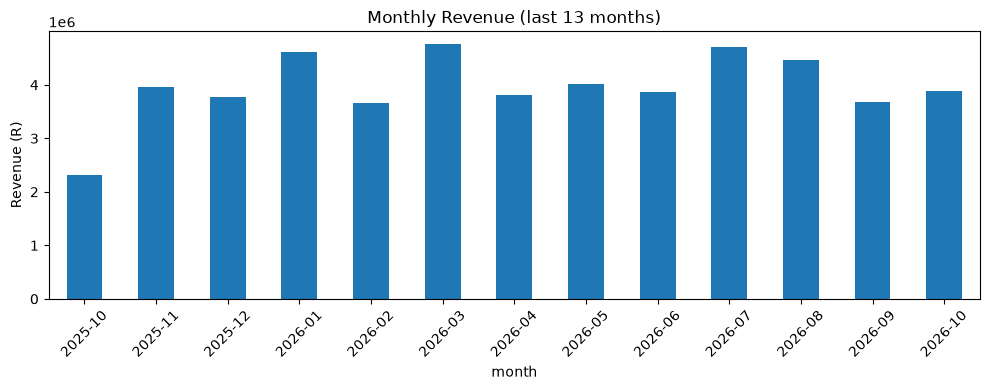

In [14]:
# Finding 1 chart
#monthly revenue

from matplotlib import pyplot as plt


mon =pd.read_sql("""
SELECT strftime('%Y-%m', order_date) AS month, SUM(quantity * unit_price) AS revenue
FROM orders_clean
where status IN ('completed', 'returned') AND order_date >=date('now','-13 months')
Group By month ORder BY month
""", con)

print(mon)

ax =mon.plot(x='month', y='revenue', kind='bar', title='Monthly Revenue (last 13 months)', legend=False ,figsize=(10,4))
ax.set_ylabel("Revenue (R)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



### Finding 2 — ...
**So what:** ...

In [26]:
# Top 10 customers by revenue

top_customers=pd.read_sql("""SELECT c.company_name, COUNT(*) AS orders,
       SUM(o.quantity*o.unit_price) AS revenue,
       AVG(o.quantity*o.unit_price) AS avg_order_value
FROM orders_clean o JOIN customers_clean c USING(customer_id)
WHERE o.status IN ('completed','returned')
GROUP BY c.company_name ORDER BY revenue DESC LIMIT 10;""",con)

print(top_customers)





   company_name  orders     revenue  avg_order_value
0  Client Co 37      32  1370307.20     42822.100000
1  Client Co 12      39  1335416.56     34241.450256
2  Client Co 21      35  1300900.75     37168.592857
3   Client Co 5      34  1288165.53     37887.221471
4  Client Co 74      30  1281550.82     42718.360667
5  Client Co 16      34  1231245.39     36213.099706
6  Client Co 58      43  1226421.43     28521.428605
7  Client Co 27      35  1214173.96     34690.684571
8  Client Co 28      30  1203863.78     40128.792667
9  Client Co 66      32  1169490.92     36546.591250


### Finding 3 — ...
**So what:** ...

In [39]:
# Delivery performance 

delivery_perf=pd.read_sql("""SELECT strftime('%Y-%m', d.promised_date) AS month ,
ROUND(100.0*SUM(d.actual_date > d.promised_date)/Count(*),1) AS delay_percentage ,
ROUND(AVG(CASE WHEN d.actual_date > d.promised_date THEN julianday(d.actual_date) - julianday(d.promised_date) END),1) AS avg_delay_days
FROM deliveries  d JOIN orders_clean o USING(order_id) WHERE o.status ='completed' 
AND d.actual_date IS NOT NULL GROUP BY month ORDER BY month""",con)
print(delivery_perf)

      month  delay_percentage  avg_delay_days
0   2025-06              26.9             5.6
1   2025-07              27.5             5.6
2   2025-08              18.3             6.0
3   2025-09              23.3             5.7
4   2025-10              25.9             6.7
5   2025-11              28.3             6.6
6   2025-12              23.2             5.6
7   2026-01              29.4             6.8
8   2026-02              22.0             5.8
9   2026-03              27.1             6.1
10  2026-04              19.7             7.5
11  2026-05              23.0             4.9
12  2026-06              23.8             5.0
13  2026-07              23.5             5.7
14  2026-08              30.1             5.3
15  2026-09              24.0             6.3
16  2026-10              34.4             6.2
17  2026-11              20.0             8.5


In [45]:
#Which service categories drive the most revenue and which one have the highest cancellation rates .Tables [orders ,products]

service_category=pd.read_sql("""SELECT p.category ,SUM(o.quantity * o.unit_price) AS revenue ,
Count(CASE WHEN o.status='cancelled' THEN 1 END) AS cancellation_count,
ROUND(100.0*Count(CASE WHEN o.status='cancelled' THEN 1 END)/Count(*),1) AS cancellation_percentage

from orders_clean o JOIN products p USING(product_id)
GROUP BY p.category ORDER BY revenue DESC

"""
,con)

print(service_category)

      category      revenue  cancellation_count  cancellation_percentage
0      Express  20353952.45                  27                      4.2
1    logistics  20318275.48                  20                      3.2
2    Logistics  16740831.44                  27                      5.2
3    Last-Mile  10012606.57                  13                      4.3
4  Warehousing   9821176.60                  17                      5.5


In [51]:
#Find orders delivered but with no matching payment

orders_without_payments = pd.read_sql("""
SELECT
    c.company_name,
    SUM(o.quantity * o.unit_price) AS at_risk_revenue
FROM orders_clean o
JOIN deliveries d USING(order_id)
LEFT JOIN payments_clean p USING(order_id)
JOIN customers_clean c USING(customer_id)
WHERE d.actual_date IS NOT NULL
  AND (
      p.order_id IS NULL
      OR julianday(p.payment_date) - julianday(o.order_date) > 30
  )
GROUP BY c.customer_id, c.company_name
ORDER BY at_risk_revenue DESC;
""", con)


print(orders_without_payments)

    company_name  at_risk_revenue
0    Client Co 9        982166.31
1   Client Co 12        890589.82
2   Client Co 27        867926.31
3   Client Co 26        821712.85
4   Client Co 48        778058.67
..           ...              ...
75   Client Co 6        232459.22
76  Client Co 23        185312.47
77  Client Co 13        155423.47
78  Client Co 63        141537.48
79   Client Co 4        122440.99

[80 rows x 2 columns]


## 4. Recommendations
1. ...
2. ...
3. ...

## 5. Caveats & Limitations
- ...
- ...

---
*Full SQL available in notebook cells above.*